In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
df = pd.read_csv('/content/Dataset.csv')

# Display dataset
print("Dataset Shape:", df.shape)
display(df.head())

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Dataset Information
print("\nDataset Information:")
df.info()

Dataset Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"



Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [3]:
# Create a copy of the dataset
netflix = df.copy()

# Select relevant columns
netflix = netflix[['title', 'type', 'director',
                   'country', 'listed_in']]

# Convert text columns to lowercase
text_columns = ['type', 'director', 'country', 'listed_in']

for col in text_columns:
    netflix[col] = netflix[col].str.lower().str.strip()

# Fill any empty text values
netflix[text_columns] = netflix[text_columns].replace('', 'unknown')

# Display processed dataset
display(netflix.head())

print("Dataset Shape:", netflix.shape)
print("Missing Values:\n", netflix.isnull().sum())

,title,type,director,country,listed_in
0,Dick Johnson Is Dead,movie,kirsten johnson,united states,documentaries
1,Ganglands,tv show,julien leclercq,france,"crime tv shows, international tv shows, tv act..."
2,Midnight Mass,tv show,mike flanagan,united states,"tv dramas, tv horror, tv mysteries"
3,Confessions of an Invisible Girl,movie,bruno garotti,brazil,"children & family movies, comedies"
4,Sankofa,movie,haile gerima,united states,"dramas, independent movies, international movies"


Dataset Shape: (8790, 5)
Missing Values:
 title        0
type         0
director     0
country      0
listed_in    0
dtype: int64


In [4]:
# Combine all content features

netflix['combined_features'] = (
    netflix['type'] + ' ' +
    netflix['director'] + ' ' +
    netflix['country'] + ' ' +
    netflix['listed_in']
)

# Display title and combined features
display(netflix[['title', 'combined_features']].head())

print("Feature Engineering Completed!")

,title,combined_features
0,Dick Johnson Is Dead,movie kirsten johnson united states documentaries
1,Ganglands,"tv show julien leclercq france crime tv shows,..."
2,Midnight Mass,"tv show mike flanagan united states tv dramas,..."
3,Confessions of an Invisible Girl,movie bruno garotti brazil children & family m...
4,Sankofa,"movie haile gerima united states dramas, indep..."


Feature Engineering Completed!


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF Vectorizer
tfidf = TfidfVectorizer(stop_words='english')

# Convert text into numerical vectors
tfidf_matrix = tfidf.fit_transform(
    netflix['combined_features']
)

print("TF-IDF Vectorization Completed!")
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("Total Features:", len(tfidf.get_feature_names_out()))

TF-IDF Vectorization Completed!
TF-IDF Matrix Shape: (8790, 6559)
Total Features: 6559


In [6]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate cosine similarity
cosine_sim = cosine_similarity(tfidf_matrix, tfidf_matrix)

print("Cosine Similarity Calculated Successfully!")
print("Similarity Matrix Shape:", cosine_sim.shape)

Cosine Similarity Calculated Successfully!
Similarity Matrix Shape: (8790, 8790)


In [7]:
# Create title index mapping
indices = pd.Series(netflix.index, index=netflix['title'].str.lower())

# Recommendation function
def recommend_movies(title, num_recommendations=10):

    title = title.lower().strip()

    if title not in indices:
        print("Title not found in Netflix dataset!")
        return

    idx = indices[title]

    # Get similarity scores
    similarity_scores = list(enumerate(cosine_sim[idx]))

    # Sort titles by similarity
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Get top recommendations
    similarity_scores = similarity_scores[1:num_recommendations+1]

    movie_indices = [i[0] for i in similarity_scores]

    recommendations = netflix.iloc[movie_indices][
        ['title', 'type', 'listed_in']
    ].copy()

    recommendations['similarity_score'] = [
        round(i[1], 3) for i in similarity_scores
    ]

    return recommendations

In [8]:
recommend_movies("Midnight Mass")

,title,type,listed_in,similarity_score
6619,Brand New Cherry Flavor,tv show,"tv dramas, tv horror, tv mysteries",0.728
7046,The Haunting of Bly Manor,tv show,"tv dramas, tv horror, tv mysteries",0.728
7076,Ratched,tv show,"tv dramas, tv horror, tv mysteries",0.728
7910,The Haunting of Hill House,tv show,"tv dramas, tv horror, tv mysteries",0.728
7962,The Originals,tv show,"tv dramas, tv horror, tv mysteries",0.728
3677,Before I Wake,movie,"horror movies, thrillers",0.695
3777,Gerald's Game,movie,"horror movies, thrillers",0.695
4174,Hush,movie,"horror movies, thrillers",0.695
6995,American Horror Story,tv show,"tv horror, tv mysteries, tv thrillers",0.684
8476,Hannibal,tv show,"tv horror, tv mysteries, tv thrillers",0.684


In [9]:
# Evaluate recommendation quality

def evaluate_recommendations(title, num_recommendations=10):

    recommendations = recommend_movies(
        title, num_recommendations
    )

    if recommendations is None:
        return

    print("Input Title:", title)
    print("Total Recommendations:", len(recommendations))

    print(
        "Average Similarity Score:",
        round(recommendations['similarity_score'].mean(), 3)
    )

    print(
        "Maximum Similarity Score:",
        recommendations['similarity_score'].max()
    )

    print(
        "Minimum Similarity Score:",
        recommendations['similarity_score'].min()
    )

    return recommendations


evaluate_recommendations("Midnight Mass")

Input Title: Midnight Mass
Total Recommendations: 10
Average Similarity Score: 0.709
Maximum Similarity Score: 0.728
Minimum Similarity Score: 0.684


,title,type,listed_in,similarity_score
6619,Brand New Cherry Flavor,tv show,"tv dramas, tv horror, tv mysteries",0.728
7046,The Haunting of Bly Manor,tv show,"tv dramas, tv horror, tv mysteries",0.728
7076,Ratched,tv show,"tv dramas, tv horror, tv mysteries",0.728
7910,The Haunting of Hill House,tv show,"tv dramas, tv horror, tv mysteries",0.728
7962,The Originals,tv show,"tv dramas, tv horror, tv mysteries",0.728
3677,Before I Wake,movie,"horror movies, thrillers",0.695
3777,Gerald's Game,movie,"horror movies, thrillers",0.695
4174,Hush,movie,"horror movies, thrillers",0.695
6995,American Horror Story,tv show,"tv horror, tv mysteries, tv thrillers",0.684
8476,Hannibal,tv show,"tv horror, tv mysteries, tv thrillers",0.684


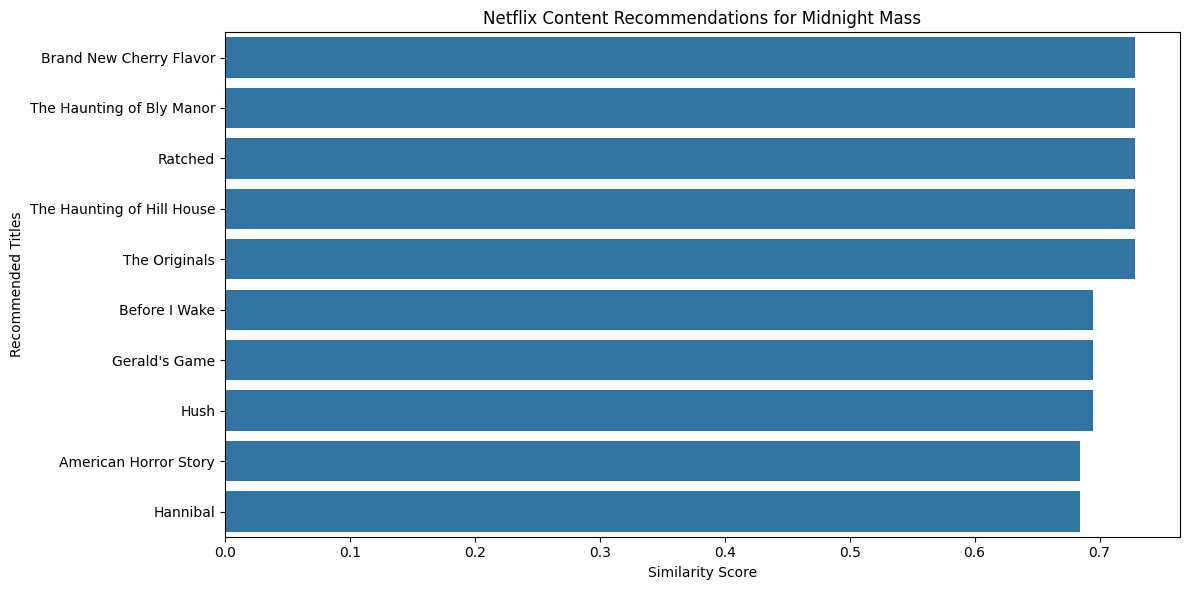

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Generate recommendations
results = recommend_movies("Midnight Mass")

# Plot recommendation scores
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results,
    x='similarity_score',
    y='title'
)

plt.title('Netflix Content Recommendations for Midnight Mass')
plt.xlabel('Similarity Score')
plt.ylabel('Recommended Titles')

plt.tight_layout()
plt.savefig('recommendation_results.png', dpi=300)
plt.show()

# Netflix Content Recommendation System

## 1. Project Overview
This project develops a content-based recommendation system
that suggests similar Netflix movies and TV shows based on
their content attributes.

## 2. Dataset
- Dataset: Netflix Titles
- Total Records: 8,790
- Total Features: 10

## 3. Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn

## 4. Methodology
1. Data Loading and Exploration
2. Data Preprocessing
3. Feature Engineering
4. TF-IDF Vectorization
5. Cosine Similarity
6. Recommendation Generation
7. Recommendation Evaluation

## 5. Model Evaluation
- Average Similarity Score: 0.709
- Maximum Similarity Score: 0.728
- Minimum Similarity Score: 0.684
- Recommendations Generated: 10

## 6. Conclusion
The system successfully recommends similar Netflix
titles using content-based filtering and cosine similarity.
It identifies related movies and TV shows based on
genres, directors, countries and content types.